# Метрики качества моделей

Мы уже умеем работать с таблицами, готовить данные и обучать линейную регрессию, логистическую регрессию и kNN. Теперь сравним их прогнозы и посмотрим, какие ошибки скрываются за одной цифрой качества.



Если `scikit-learn` не установлен, раскомментируйте следующую строку.

In [16]:
%pip install scikit-learn
%pip install matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.datasets import load_breast_cancer, load_diabetes, load_wine, load_linnerud
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error,
)

## Что происходит при обучении

`X` — таблица признаков: то, что мы знаем об объектах. `y` — правильные ответы, по которым модель учится. Например, в `X` находятся измерения, а в `y` — класс каждого образца.

Когда вызываем `model.fit(X_train, y_train)`, мы даём модели примеры вместе с ответами. Что она сохраняет, зависит от алгоритма:

| Модель | Что происходит в `.fit()` | Как получается новый прогноз |
|---|---|---|
| Линейная регрессия | Находит коэффициенты, минимизирующие сумму квадратов ошибок на train | Подставляет признаки в линейную формулу |
| Логистическая регрессия | Подбирает коэффициенты, уменьшая ошибку предсказанных вероятностей с учётом регуляризации | Считает линейную оценку, переводит её в вероятность и выбирает класс |
| kNN | Сохраняет обучающие объекты и их ответы | Находит ближайшие объекты и использует их ответы |

У kNN нет такого же подбора коэффициентов, как у регрессий. В классификации соседи голосуют за класс, а в регрессии их числовые ответы усредняются.

## Почему сначала делим данные

Обучающая часть нужна для подбора модели. Тестовая часть играет роль новых объектов: при обучении их ответы модель не видит.

1. Делим `X` и `y` вместе, чтобы признаки и ответы оставались согласованными.
2. Вызываем `.fit(X_train, y_train)`.
3. Вызываем `.predict(X_test)`: на этом шаге передаём только признаки.
4. Сравниваем прогнозы с `y_test` через метрики.

Если считать метрики на обучающих объектах, можно увидеть хорошую оценку запоминания вместо качества на новых данных.

`test_size=0.25` оставляет четверть объектов для теста. `random_state` фиксирует случайное разделение. Для классификации `stratify=y` сохраняет примерно одинаковые доли классов в обеих частях.

Сегодня сравниваем заранее выбранные модели на одном тесте. Для подбора настроек понадобилась бы отдельная проверочная часть.

## Масштабирование и pipeline

`StandardScaler` для каждого признака запоминает среднее и стандартное отклонение по train. Затем вычитает это среднее и делит на это отклонение. Признаки получают сопоставимый масштаб.

Это особенно важно для kNN: иначе признак с большими числами может почти полностью определять расстояния. Масштабирование также помогает обучению логистической регрессии.

Pipeline соединяет обработку с моделью:

- при `.fit()` scaler учится на train, преобразует его и передаёт модели;
- при `.predict()` тот же scaler преобразует тестовые признаки, затем модель делает прогнозы.

Средние и отклонения на тесте заново не вычисляются. Правильные ответы `y` scaler не меняет.

# Бинарная классификация

Вернёмся к реальным данным Wisconsin Breast Cancer. Каждая строка содержит измерения клеток одного образца.

В исходном наборе `0` означает злокачественную опухоль. Для этого примера сделаем **злокачественную опухоль классом `1`**, чтобы precision и recall описывали её обнаружение. Выбор положительного класса нужно явно оговаривать.

In [18]:
cancer = load_breast_cancer(as_frame=True)
cancer_data = cancer.data.copy()
cancer_data["Malignant"] = (cancer.target == 0).astype(int)

display(cancer_data.head())
print("Размер:", cancer_data.shape)
print("Пропуски:", cancer_data.isna().sum().sum())
print("Полные дубликаты:", cancer_data.duplicated().sum())
print(cancer_data["Malignant"].value_counts().sort_index())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


Размер: (569, 31)
Пропуски: 0
Полные дубликаты: 0
Malignant
0    357
1    212
Name: count, dtype: int64


## Признаки и разделение

`.drop(columns=...)` оставляет признаки без правильного ответа. `stratify=y` сохраняет примерно те же доли классов в обеих частях. `random_state` делает разделение повторяемым.

In [19]:
cancer_X = cancer_data.drop(columns="Malignant")
cancer_y = cancer_data["Malignant"]

cancer_X_train, cancer_X_test, cancer_y_train, cancer_y_test = train_test_split(
    cancer_X, cancer_y, test_size=0.25, random_state=42, stratify=cancer_y,
)

cancer_logistic = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
cancer_logistic.fit(cancer_X_train, cancer_y_train)
cancer_pred = cancer_logistic.predict(cancer_X_test)
cancer_probability = cancer_logistic.predict_proba(cancer_X_test)[:, 1]

print("Порядок классов:", cancer_logistic.classes_)
display(pd.DataFrame({
    "Actual": cancer_y_test.to_numpy(),
    "Predicted": cancer_pred,
    "Probability_1": cancer_probability,
}).head(10).round(3))

Порядок классов: [0 1]


,Actual,Predicted,Probability_1
0,1,1,0.999
1,0,0,0.004
2,1,1,1.000
3,0,0,0.000
4,0,0,0.035
5,0,0,0.004
6,0,0,0.000
7,0,0,0.002
8,0,0,0.007
9,0,0,0.099


## Разберём вызов `.fit()`

В `cancer_X_train` находятся признаки, в `cancer_y_train` — правильные классы этих же строк. Pipeline сначала масштабирует признаки, затем логистическая регрессия подбирает коэффициенты.

Общая идея обучения такая: начинаем с начальных коэффициентов, считаем вероятности на train, оцениваем ошибку и меняем коэффициенты, чтобы уменьшить цель обучения. Библиотека выполняет эти вычисления сама. `max_iter=2000` задаёт верхнюю границу числа итераций, обучение может закончиться раньше.

После `.fit()` коэффициенты сохраняются. Во время `.predict()` обучение заново не запускается.

Для бинарной задачи в scikit-learn `.predict()` выбирает класс с большей вероятностью. Обычно это соответствует порогу 0.5. `.predict_proba()` позволяет увидеть обе вероятности, столбцы идут в порядке `.classes_`.

In [20]:
# Pipeline состоит из scaler и самой модели.
trained_scaler = cancer_logistic.named_steps["standardscaler"]
trained_logistic = cancer_logistic.named_steps["logisticregression"]

print("Признаков у модели:", trained_logistic.coef_.shape[1])
print("Коэффициентов свободного члена:", trained_logistic.intercept_.shape[0])
print("Выполнено итераций:", trained_logistic.n_iter_[0])

# Получаем прогнозы для трёх новых для модели строк.
new_samples = cancer_X_test.iloc[:3]
print("Прогнозы:", cancer_logistic.predict(new_samples))
print("Вероятности:")
print(cancer_logistic.predict_proba(new_samples).round(3))

Признаков у модели: 30
Коэффициентов свободного члена: 1
Выполнено итераций: 20
Прогнозы: [1 0 1]
Вероятности:
[[0.001 0.999]
 [0.996 0.004]
 [0.    1.   ]]


## Матрица ошибок

Строки матрицы — настоящие классы, столбцы — прогнозы. С `labels=[0, 1]` порядок фиксирован:

| | Прогноз 0 | Прогноз 1 |
|---|---|---|
| Настоящий 0 | TN | FP |
| Настоящий 1 | FN | TP |

FP — ложная тревога. FN — пропущенный объект класса `1`. `.ravel()` разворачивает четыре ячейки в последовательность `TN, FP, FN, TP`.

TN: 89 FP: 1 FN: 4 TP: 49


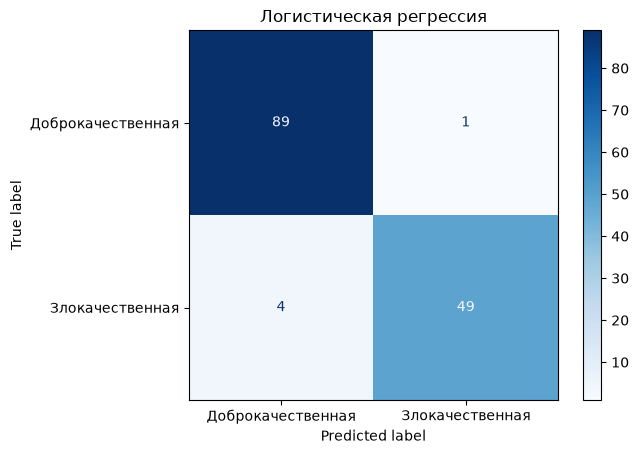

In [21]:
cancer_cm = confusion_matrix(cancer_y_test, cancer_pred, labels=[0, 1])
tn, fp, fn, tp = cancer_cm.ravel()
print("TN:", tn, "FP:", fp, "FN:", fn, "TP:", tp)

ConfusionMatrixDisplay(cancer_cm, display_labels=["Доброкачественная", "Злокачественная"]).plot(cmap="Blues")
plt.title("Логистическая регрессия")
plt.show()

## Accuracy, precision, recall и F1

| Метрика | Что считаем | Что означает |
|---|---|---|
| Accuracy | `(TP + TN) / N` | Доля всех правильных ответов |
| Precision | `TP / (TP + FP)` | Какая доля прогнозов класса 1 верна |
| Recall | `TP / (TP + FN)` | Какую долю настоящего класса 1 нашли |
| F1 | `2 × precision × recall / (precision + recall)` | Совместная оценка precision и recall |

Все четыре метрики здесь лучше при больших значениях. В функции сначала передаём настоящие ответы, затем прогнозы. `zero_division=0` возвращает 0, если знаменатель метрики равен нулю.

In [22]:
print("Accuracy:", round(accuracy_score(cancer_y_test, cancer_pred), 3))
print("Precision:", round(precision_score(cancer_y_test, cancer_pred, zero_division=0), 3))
print("Recall:", round(recall_score(cancer_y_test, cancer_pred, zero_division=0), 3))
print("F1:", round(f1_score(cancer_y_test, cancer_pred, zero_division=0), 3))

print("Precision вручную:", tp / (tp + fp))
print("Recall вручную:", tp / (tp + fn))

Accuracy: 0.965
Precision: 0.98
Recall: 0.925
F1: 0.951
Precision вручную: 0.98
Recall вручную: 0.9245283018867925


## Когда accuracy недостаточно

Повторим пример спам-фильтра из презентации. Класс `1` — спам. Сравним фильтр с правилом «все письма обычные». Для этой маленькой иллюстрации задаём ответы напрямую, без обучения.

In [23]:
mail_true = np.array([0] * 100 + [1] * 10)
mail_filter = np.array([0] * 90 + [1] * 10 + [1] * 5 + [0] * 5)
mail_all_normal = np.zeros(len(mail_true), dtype=int)

mail_rows = []
for name, pred in [("Спам-фильтр", mail_filter), ("Все письма обычные", mail_all_normal)]:
    mail_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(mail_true, pred),
        "Precision": precision_score(mail_true, pred, zero_division=0),
        "Recall": recall_score(mail_true, pred, zero_division=0),
        "F1": f1_score(mail_true, pred, zero_division=0),
    })
display(pd.DataFrame(mail_rows).round(3))

,Model,Accuracy,Precision,Recall,F1
0,Спам-фильтр,0.864,0.333,0.5,0.4
1,Все письма обычные,0.909,0.000,0.0,0.0


Вторая модель получает более высокую accuracy, хотя не находит ни одного спам-письма. Accuracy остаётся полезной метрикой, но при неравных классах её нужно смотреть вместе с другими показателями.

## Порог классификации

Модель уже обучена. Меняем только правило перевода вероятности в класс. `(probability >= threshold).astype(int)` превращает условие в нули и единицы.

Ниже исследуем влияние порога. Эти значения не подбирают «лучший порог» для будущего использования. Для такого выбора нужна проверочная выборка.

In [24]:
threshold_rows = []
for threshold in [0.2, 0.5, 0.8]:
    threshold_pred = (cancer_probability >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Predicted_1": threshold_pred.sum(),
        "Precision": precision_score(cancer_y_test, threshold_pred, zero_division=0),
        "Recall": recall_score(cancer_y_test, threshold_pred, zero_division=0),
        "F1": f1_score(cancer_y_test, threshold_pred, zero_division=0),
    })
display(pd.DataFrame(threshold_rows).round(3))

,Threshold,Predicted_1,Precision,Recall,F1
0,0.2,54,0.944,0.962,0.953
1,0.5,50,0.980,0.925,0.951
2,0.8,46,1.000,0.868,0.929


## Сравним логистическую регрессию и kNN

Обучим kNN с пятью соседями. Во время `.fit()` он сохранит масштабированные признаки train и их классы. Для нового объекта найдёт пять ближайших обучающих объектов и выберет класс с большинством голосов. При обычных равных весах вероятность класса — доля соседей этого класса.

Обе модели используют одинаковые обучающие и тестовые данные. Сравним несколько метрик, чтобы увидеть разные стороны качества.

In [25]:
cancer_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
cancer_knn.fit(cancer_X_train, cancer_y_train)

classification_rows = []
for name, model in [("LogisticRegression", cancer_logistic), ("kNN", cancer_knn)]:
    pred = model.predict(cancer_X_test)
    probability = model.predict_proba(cancer_X_test)[:, 1]
    classification_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(cancer_y_test, pred),
        "Precision": precision_score(cancer_y_test, pred, zero_division=0),
        "Recall": recall_score(cancer_y_test, pred, zero_division=0),
        "F1": f1_score(cancer_y_test, pred, zero_division=0),
    })
display(pd.DataFrame(classification_rows).round(3))

,Model,Accuracy,Precision,Recall,F1
0,LogisticRegression,0.965,0.98,0.925,0.951
1,kNN,0.958,0.98,0.906,0.941


# Метрики регрессии

Для числового ответа оставим две основные метрики: MAE и MSE.

| Метрика | Как читать | Лучше |
|---|---|---|
| MAE | Средняя абсолютная ошибка в единицах ответа | Меньше |
| MSE | Средний квадрат ошибки, большие промахи влияют сильнее | Меньше |

## Что учит линейная регрессия

Возьмём один признак, чтобы увидеть обучение в простой формуле: `прогноз = b₀ + b₁ × x`.

До `.fit()` коэффициенты ещё не подобраны по нашим данным. `.fit()` находит такие `b₀` и `b₁`, при которых сумма квадратов ошибок на train минимальна. Для обычной линейной регрессии библиотека решает задачу наименьших квадратов, нам не нужно вручную менять коэффициенты.

После обучения `.intercept_` хранит `b₀`, а `.coef_` хранит коэффициенты признаков. При нескольких признаках формула содержит несколько слагаемых.

На новом объекте коэффициенты уже фиксированы: модель подставляет признаки и получает число. Хорошее совпадение на train ещё не гарантирует точные прогнозы на тесте.

b₀: 33.933 b₁: 6.114
Через predict: 76.73333333333333
Через формулу: 76.73333333333333


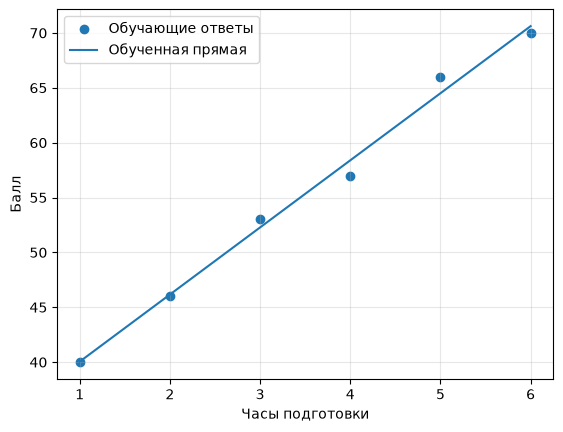

In [26]:
# Небольшой пример для наблюдения за обучением.
training_hours = pd.DataFrame({"Hours": [1, 2, 3, 4, 5, 6]})
training_scores = pd.Series([40, 46, 53, 57, 66, 70])

training_linear = LinearRegression()
training_linear.fit(training_hours, training_scores)

b0 = training_linear.intercept_
b1 = training_linear.coef_[0]
print("b₀:", round(b0, 3), "b₁:", round(b1, 3))

new_student = pd.DataFrame({"Hours": [7]})
print("Через predict:", training_linear.predict(new_student)[0])
print("Через формулу:", b0 + b1 * 7)

plt.scatter(training_hours["Hours"], training_scores, label="Обучающие ответы")
plt.plot(training_hours["Hours"], training_linear.predict(training_hours), label="Обученная прямая")
plt.xlabel("Часы подготовки")
plt.ylabel("Балл")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Большие ошибки: MAE и MSE

В первом прогнозе все ошибки небольшие. Во втором большинство ответов точные, но один промах большой. Посмотрим, как меняются метрики.

In [27]:
number_true = np.array([10, 20, 30, 40, 50])
number_pred_a = np.array([14, 24, 34, 44, 54])
number_pred_b = np.array([10, 20, 30, 40, 65])

error_rows = []
for name, pred in [("A", number_pred_a), ("B", number_pred_b)]:
    error_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(number_true, pred),
        "MSE": mean_squared_error(number_true, pred),
    })
display(pd.DataFrame(error_rows))

,Model,MAE,MSE
0,A,4.0,16.0
1,B,3.0,45.0


## Реальные данные и простой ориентир

Набор Diabetes содержит 442 наблюдения и числовой показатель прогрессирования заболевания через год. Это повторение знакомой задачи, теперь сравним качество нескольких правил.

Сначала посмотрим на данные и разделим их. Признаки в этом наборе уже масштабированы его создателями.

In [28]:
diabetes = load_diabetes(as_frame=True)
diabetes_data = diabetes.frame
display(diabetes_data.head())
print("Пропуски:", diabetes_data.isna().sum().sum())

diabetes_X = diabetes_data.drop(columns="target")
diabetes_y = diabetes_data["target"]
diabetes_X_train, diabetes_X_test, diabetes_y_train, diabetes_y_test = train_test_split(
    diabetes_X, diabetes_y, test_size=0.25, random_state=42,
)

diabetes_linear = LinearRegression()
diabetes_linear.fit(diabetes_X_train, diabetes_y_train)
diabetes_pred = diabetes_linear.predict(diabetes_X_test)

# Простой прогноз: одно среднее, рассчитанное только по обучающим ответам.
diabetes_baseline = np.full(len(diabetes_y_test), diabetes_y_train.mean())

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


Пропуски: 0


In [29]:
regression_rows = []
for name, pred in [("Среднее train", diabetes_baseline), ("LinearRegression", diabetes_pred)]:
    regression_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(diabetes_y_test, pred),
        "MSE": mean_squared_error(diabetes_y_test, pred),
    })
display(pd.DataFrame(regression_rows).round(3))

,Model,MAE,MSE
0,Среднее train,65.527,5607.198
1,LinearRegression,41.549,2848.311


## Проверим отдельные промахи

Добавим настоящие ответы и прогнозы в одну таблицу. `abs()` берёт модуль, `.sort_values()` помогает найти самые большие ошибки. Их стоит проверить отдельно, даже если средняя метрика выглядит хорошо.

,Actual,Prediction,AbsoluteError
56,52.0,205.7,153.7
380,52.0,185.6,133.6
77,200.0,71.2,128.8
211,70.0,182.5,112.5
209,77.0,187.2,110.2
9,310.0,204.4,105.6
239,262.0,166.0,96.0
354,272.0,177.6,94.4
131,158.0,63.8,94.2
395,258.0,165.8,92.2


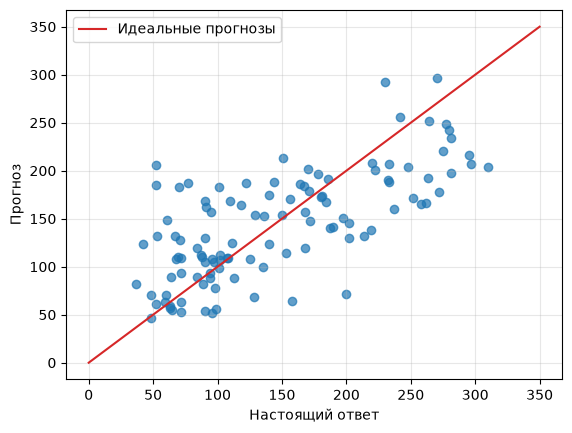

In [30]:
diabetes_errors = pd.DataFrame({
    "Actual": diabetes_y_test.to_numpy(),
    "Prediction": diabetes_pred,
}, index=diabetes_y_test.index)
diabetes_errors["AbsoluteError"] = (diabetes_errors["Prediction"] - diabetes_errors["Actual"]).abs()
display(diabetes_errors.sort_values("AbsoluteError", ascending=False).head(10).round(1))

plt.scatter(diabetes_errors["Actual"], diabetes_errors["Prediction"], alpha=0.7)
plt.plot([0, 350], [0, 350], color="tab:red", label="Идеальные прогнозы")
plt.xlabel("Настоящий ответ")
plt.ylabel("Прогноз")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Почему результат 1.00 стоит проверить

Очень высокая метрика может быть настоящим результатом. Но сначала проверьте, что целевая переменная не попала в признаки, данные не дублируются между частями и метрика рассчитана на тесте.

Ниже покажем, как хорошо kNN с одним соседом запоминает обучающие объекты. Это не проверка качества на новых данных.

In [31]:
memorizing_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1))
memorizing_knn.fit(cancer_X_train, cancer_y_train)
print("Accuracy train:", accuracy_score(cancer_y_train, memorizing_knn.predict(cancer_X_train)))
print("Accuracy test:", accuracy_score(cancer_y_test, memorizing_knn.predict(cancer_X_test)))

Accuracy train: 1.0
Accuracy test: 0.9370629370629371


# Задания



## Задание 1. Регрессия: физические показатели

Набор Linnerud содержит данные 20 участников: число подтягиваний (`Chins`), подъёмов корпуса (`Situps`) и прыжков (`Jumps`), а также физические показатели. Попробуем предсказывать вес `Weight` (в фунтах) по результатам упражнений.

Набор маленький: метрики на пяти тестовых участниках могут сильно зависеть от разделения. Это часть задачи, а не гарантия сильной зависимости.

1. Выведите первые строки, размер, число пропусков и дубликатов.
2. Создайте `X` из трёх упражнений и `y` из `Weight`.
3. Разделите данные с `test_size=0.25`, `random_state=42`.
4. Обучите `LinearRegression` и pipeline из `StandardScaler` и `KNeighborsRegressor(n_neighb
5. ors=3)`.
6. Создайте постоянный прогноз среднего веса по train.
7. Соберите таблицу MAE и MSE для трёх вариантов.
8. Кодом выведите название варианта с минимальной MAE.
9. Для линейной регрессии выведите настоящие ответы, прогнозы и абсолютные ошибки, отсортированные по убыванию ошибки.

`KNeighborsRegressor` работает с числовым ответом и усредняет ответы соседей. В остальном используем знакомые `.fit()` и `.predict()`.

In [69]:
import pandas as pd



exercise_fitness = load_linnerud(as_frame=True)
fitness_data = exercise_fitness.data.copy()
fitness_data["Weight"] = exercise_fitness.target["Weight"]
display(fitness_data.head())

# Напишите решение здесь

print('#1')

fitness_data.head()
fitness_data.shape
fitness_data.isna().sum().sum()
fitness_data.duplicated().sum()

print('#2')

fitness_data_X = fitness_data.drop(columns = 'Weight')
fitness_data_y = fitness_data['Weight']

print('#3')

train_X, test_X, train_y, test_y  = train_test_split(fitness_data_X, fitness_data_y, test_size=0.25, random_state=42 )

print('#4')

model1 = LinearRegression()
model1.fit(train_X, train_y)
model2 = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=3))
model2.fit(train_X, train_y)

test1 = model1.predict(test_X)
test2 = model2.predict(test_X)
print('#5')

const_pred = np.full(len(test_y), train_y.mean())
display(const_pred)


print('#6')

mae_lin = mean_absolute_error(test_y,test1)
mse_lin = mean_squared_error(test_y,test1)

mae_knn = mean_absolute_error(test_y,test2)
mse_knn = mean_squared_error(test_y,test2)

mae_const = mean_absolute_error(test_y, const_pred)
mse_const = mean_squared_error(test_y, const_pred)
print('#7')
data = pd.DataFrame( {
    'MAE':[mae_lin,mae_knn,mae_const],
    'MSE':[mse_lin, mse_knn, mse_const]
    },
    index = ['Лин Регрессия','Knn','Mean']   
       )
display(data)
    
print('#8')
print('мин мсе:',data['MSE'].idxmin() )
print('мин мае:', data['MAE'].idxmin() )


print('#9')

predicts = model1.predict(test_X)
abs_error = np.abs(test_y-predicts)

df = pd.DataFrame({
    'Ответы': test_y,
    'Предикты': predicts,
    'абс ошибка' : abs_error
}  
)


new_data = df.sort_values(by='абс ошибка', ascending=False).reset_index(drop=True)

display(new_data)

,Chins,Situps,Jumps,Weight
0,5.0,162.0,60.0,191.0
1,2.0,110.0,60.0,189.0
2,12.0,101.0,101.0,193.0
3,12.0,105.0,37.0,162.0
4,13.0,155.0,58.0,189.0


#1
#2
#3
#4
#5


array([177.13333333, 177.13333333, 177.13333333, 177.13333333,
       177.13333333])

#6
#7


,MAE,MSE
Лин Регрессия,24.404029,765.484945
Knn,22.000000,701.377778
Mean,14.373333,271.617778


#8
мин мсе: Mean
мин мае: Mean
#9


,Ответы,Предикты,абс ошибка
0,202.0,156.805421,45.194579
1,191.0,163.116984,27.883016
2,176.0,148.708618,27.291382
3,157.0,142.419015,14.580985
4,189.0,181.929817,7.070183


## Задание 2. Классификация: две разновидности вина

Набор Wine содержит химические измерения вин трёх разновидностей. В этом задании оставим только разновидности `1` и `2` и пять химических показателей. Разновидность `2` станет положительным классом `1`, а разновидность `1` — классом `0`.

1. Выведите число объектов каждого класса, размер и количество пропусков.
2. Создайте `X` и `y`, исключив `IsClass2` из признаков.
3. Разделите данные с `test_size=0.25`, `random_state=7`, `stratify=y`.
4. Обучите два pipeline со `StandardScaler`: логистическую регрессию и kNN с пятью соседями.
5. Соберите таблицу accuracy, precision, recall и F1 для обеих моделей.
6. Постройте матрицу ошибок логистической регрессии и выведите TN, FP, FN, TP.
7. Для логистической регрессии получите классы при порогах `0.3`, `0.5`, `0.7` и соберите таблицу precision, recall и F1.
8. Выведите первые 10 настоящих классов, прогнозов и вероятностей класса 1 логистической регрессии в одной таблице.

Здесь исследуем пороги, без выбора настроек по тесту.

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,IsClass2
59,12.37,0.94,1.36,10.6,88.0,0
60,12.33,1.10,2.28,16.0,101.0,0
61,12.64,1.36,2.02,16.8,100.0,0
62,13.67,1.25,1.92,18.0,94.0,0
63,12.37,1.13,2.16,19.0,87.0,0


класс 0: 71
класс 1: 48
Размер датасета: (119, 6)
Количество пропусков: 0


,Accuracy,Precision,Recall,F1
Logistic Regression,0.966667,1.000000,0.916667,0.956522
KNN,0.933333,0.916667,0.916667,0.916667


TN :  18
FP : 0
FN : 1
TP :  11


,Precision,Recall,F1
Порог,,,
0.3,0.923077,1.000000,0.960000
0.5,1.000000,0.916667,0.956522
0.7,1.000000,0.500000,0.666667


,Настоящий класс,Прогноз,Вероятность класса 1
98,0,0,0.052576
82,0,0,0.033543
101,0,0,0.057852
146,1,1,0.963681
132,1,0,0.312432
148,1,1,0.766406
159,1,1,0.687918
105,0,0,0.163061
106,0,0,0.056161
84,0,0,0.076095


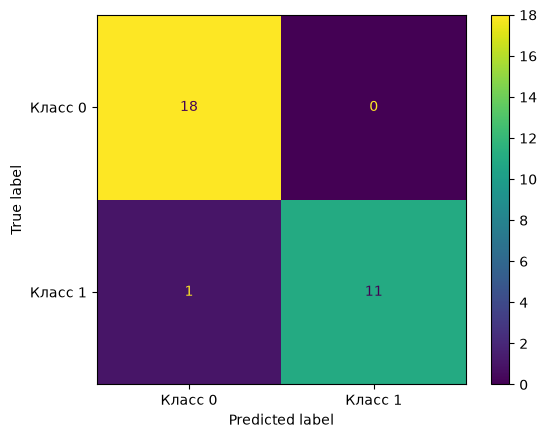

In [119]:
from sklearn.neighbors import KNeighborsClassifier

exercise_wine = load_wine(as_frame=True)
wine_mask = exercise_wine.target.isin([1, 2])
wine_features = ["alcohol", "malic_acid", "ash", "alcalinity_of_ash", "magnesium"]
exercise_wine_data = exercise_wine.data.loc[wine_mask, wine_features].copy()
exercise_wine_data["IsClass2"] = (exercise_wine.target.loc[wine_mask] == 2).astype(int)
display(exercise_wine_data.head())

# Напишите решение здесь

print('класс 0:',(exercise_wine_data['IsClass2'] == 0).sum())
print('класс 1:',(exercise_wine_data['IsClass2'] == 1).sum())

print('Размер датасета:', exercise_wine_data.shape)

print('Количество пропусков:', exercise_wine_data.isna().sum().sum())

X = exercise_wine_data.drop(columns = 'IsClass2')
y = exercise_wine_data['IsClass2']


train_X, test_X, train_y, test_y = train_test_split( X, y, test_size=0.25, random_state=7, stratify=y)

model11 = make_pipeline(StandardScaler(), LogisticRegression())
model12 = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

model11.fit(train_X,train_y)
model12.fit(train_X, train_y)

model11_pred = model11.predict(test_X)
model12_pred = model12.predict(test_X)


model11_cm = confusion_matrix(test_y, model11_pred, labels=[0, 1])
model12_cm = confusion_matrix(test_y, model12_pred, labels=[0, 1])



metrics_table = pd.DataFrame({
    'Accuracy': [
        accuracy_score(test_y, model11_pred),
        accuracy_score(test_y, model12_pred)
    ],
    'Precision': [
        precision_score(test_y, model11_pred),
        precision_score(test_y, model12_pred)
    ],
    'Recall': [
        recall_score(test_y, model11_pred),
        recall_score(test_y, model12_pred)
    ],
    'F1': [
        f1_score(test_y, model11_pred),
        f1_score(test_y, model12_pred)
    ]
}, index=['Logistic Regression', 'KNN '])
display(metrics_table)

cm = confusion_matrix(test_y, model11_pred, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

print(f"TN :  {tn}")
print(f"FP : {fp}")
print(f"FN : {fn}")
print(f"TP :  {tp}")

ConfusionMatrixDisplay.from_predictions(test_y, model11_pred, display_labels=['Класс 0', 'Класс 1'])


probs = model11.predict_proba(test_X)[:, 1]
thresholds = [0.3, 0.5, 0.7]
results = []

for th in thresholds:
    pred_th = (probs >= th).astype(int)
    
    results.append({
        'Порог': th,
        'Precision': precision_score(test_y, pred_th),
        'Recall': recall_score(test_y, pred_th),
        'F1': f1_score(test_y, pred_th)
    })

threshold_table = pd.DataFrame(results).set_index('Порог')
display(threshold_table)


preds = model11.predict(test_X)
probs = model11.predict_proba(test_X)[:, 1]

df_comparison = pd.DataFrame({
    'Настоящий класс': test_y,
    'Прогноз': preds,
    'Вероятность класса 1': probs
})

display(df_comparison.head(10))